In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torchvision import transforms
from torchvision.datasets import EuroSAT


dataset = EuroSAT(
    root=Path("../data"),
    download=True,
)

to_tensor = transforms.ToTensor()

def add_gaussian_noise(image, std=0.1):
    image_tensor = to_tensor(image)
    noise = torch.randn_like(image_tensor) * std
    noisy = image_tensor + noise
    return noisy.clamp(0.0, 1.0)

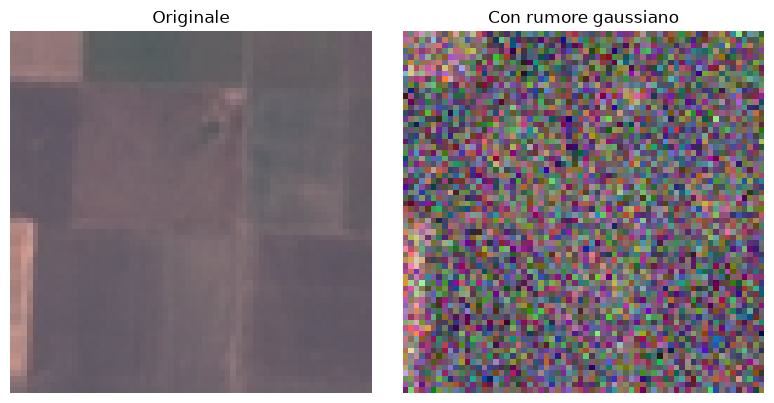

In [6]:
image, label = dataset[0]
clean = to_tensor(image)
noisy = add_gaussian_noise(image, std=0.15)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(clean.permute(1, 2, 0))
axes[0].set_title("Originale")
axes[0].axis("off")

axes[1].imshow(noisy.permute(1, 2, 0))
axes[1].set_title("Con rumore gaussiano")
axes[1].axis("off")

plt.tight_layout()